In [ ]:
from google.colab import files
import pandas as pd

df = pd.read_excel("MAFLD Data Final Merged.xlsx")
df.head()

,SubmissionDate,Today,I7,end,deviceid,unique id,Gender,age,recruitment_details-date_of_intial_visit,Medical history,...,KEY,SubmitterID,SubmitterName,AttachmentsPresent,AttachmentsExpected,Status,ReviewState,DeviceID,Edits,FormVersion
0,2025-10-13T11:12:51.710Z,2025-10-13,2025-10-13T12:05:21.534+05:30,2025-10-13T15:26:12.541+05:30,collect:LyP1i2tmZI1ET95b,1140.0,1,35,2025-10-13,1 2,...,uuid:6a753694-0b3b-4ba0-ab69-b71e54ddc152,308,MAFLD,0,0,NaN,NaN,collect:LyP1i2tmZI1ET95b,0,2025091611
1,2025-10-06T11:13:24.825Z,2025-10-06,2025-10-06T10:43:32.421+05:30,2025-10-06T16:08:26.491+05:30,collect:LyP1i2tmZI1ET95b,1021.0,1,35,2025-10-06,1,...,uuid:c39d527b-2c1a-4cae-89f1-22aee59b2ddb,308,MAFLD,0,0,NaN,NaN,collect:LyP1i2tmZI1ET95b,0,2025091611
2,2025-11-11T08:35:20.699Z,2025-11-11,2025-11-11T10:23:38.122+05:30,2025-11-11T12:55:22.797+05:30,collect:cF5vZuaCXMLr90zP,3100.0,1,35,2025-11-11,1,...,uuid:3213bd49-c0af-4425-96ae-4424155e2570,308,MAFLD,0,0,NaN,NaN,collect:cF5vZuaCXMLr90zP,0,2025091612
3,2025-10-15T09:01:29.968Z,2025-10-15,2025-10-15T11:47:59.899+05:30,2025-10-15T14:28:38.497+05:30,collect:cF5vZuaCXMLr90zP,3007.0,1,35,2025-10-15,1 2,...,uuid:44b4220d-c16b-48f4-9fae-2cbe8452a9d5,308,MAFLD,0,0,NaN,NaN,collect:cF5vZuaCXMLr90zP,0,2025091611
4,2025-10-15T09:01:27.747Z,2025-10-15,2025-10-15T11:12:24.869+05:30,2025-10-15T14:26:35.330+05:30,collect:cF5vZuaCXMLr90zP,3004.0,2,35,2025-10-15,1,...,uuid:beb9eb47-422c-4245-a5b3-604f368a5904,308,MAFLD,0,0,NaN,NaN,collect:cF5vZuaCXMLr90zP,0,2025091611


In [ ]:
for col in df.columns:
    print(col)

SubmissionDate
Today
I7
end
deviceid
unique id
Gender
age
recruitment_details-date_of_intial_visit
Medical history
medical_family_history-disease_others
Diabetes duration
hypertension duration
fatty_liver_block-fatty_know
fatty_liver_block-fatty_know_others
fatty_liver_block-diagnosis_date
fatty_liver_block-diagnosis_method
fatty_liver_block-diagnosis_method_others
fatty_liver_block-treatment_status
fatty_liver_block-end_note
Alcohol ever
Alcohol 12m
Alcohol drinks
Alcohol duration
Smoking habbit
Tobacco type
behavioural_risk_factors-tobacco_details-tobacco_type_others
bp_measurement-systolic_1
bp_measurement-diastolic_1
bp_measurement-BP1_updateTime
bp_measurement-BP1_recordTime
bp_measurement-systolic_2
bp_measurement-diastolic_2
bp_measurement-BP2_updateTime
bp_measurement-systolic_3
bp_measurement-diastolic_3
bp_measurement-BP3_updateTime
bp_measurement-avg_systolic
bp_measurement-avg_diastolic
Height
weight
bmi
BMI category
anthropometric_measurement-show_bmi
Waist circumference
H

In [ ]:
remove_columns = [
    'HSI Index',
    'ALT AST ratio',
    'FIB 4 score',
    'rbs',
    'lipid',
    'weight',
    'meta-entity-label',
    'meta-instanceID',
    'bp_measurement-systolic_1',
    'bp_measurement-systolic_2',
    'bp_measurement-systolic_3',
    'bp_measurement-diastolic_1',
    'bp_measurement-diastolic_2',
    'bp_measurement-diastolic_3'
    'alt',
    'Ast',
    'cholesterol',
    'triglycerides',
    'hdl',
    'ldl',
    'glucose',
    'hba1c'
]
top_feature_names = [
    'bmi',
    'Hip circumference',
    'age',
    'Waist circumference',
    'bp_measurement-avg_systolic',
    'bp_measurement-avg_diastolic',
]

X_selected = df[top_feature_names]

print(X_selected.head())
X_selected = X_selected.drop(
    columns=remove_columns,
    errors='ignore'
)

available_features = []
required_features = top_feature_names
for col in required_features:
    if col in X_selected.columns:
        available_features.append(col)
    elif col in df.columns:
        X_selected[col] = df[col]
        available_features.append(col)

X_selected = X_selected[available_features]
y = df['HIS Category']

print("Selected Features:")
print(X_selected.columns.tolist())

print("\nShape:")
print(X_selected.shape)

    bmi  Hip circumference  age  Waist circumference  \
0  29.7                 86   35                   80   
1  27.1                106   35                  102   
2  30.7                113   35                  108   
3  16.4                 93   35                   87   
4  18.4                117   35                   98   

   bp_measurement-avg_systolic  bp_measurement-avg_diastolic  
0                          100                            80  
1                          120                            75  
2                          133                            80  
3                          115                            75  
4                          120                            80  
Selected Features:
['bmi', 'Hip circumference', 'age', 'Waist circumference', 'bp_measurement-avg_systolic', 'bp_measurement-avg_diastolic']

Shape:
(537, 6)


In [ ]:
import numpy as np
from typing import Any, Dict
from numpy.typing import ArrayLike
from sklearn.base import clone
import copy
from xgboost import XGBClassifier

class XGBOrdinal(XGBClassifier):
    def __init__(self, aggregation='weighted', norm=True, **extra_params):
        # Initialize the ordinal classifier
        self.clf = XGBClassifier
        self.aggregation = aggregation
        self.norm = norm
        self.model_weights = None  # Weighting for model
        self.kwargs = extra_params  # Store extra parameters
        super().__init__(**extra_params)

    def set_model_weights(self, y):
        # Calculate model weights based on aggregation type
        if self.aggregation == 'weighted':
            class_dist = np.bincount(y)
            absolute_model_weights = class_dist[:-1] + class_dist[1:]
            self.model_weights = (absolute_model_weights) / np.sum(absolute_model_weights)
        elif self.aggregation == 'equal':
            self.model_weights = np.full((self.number_clfs,), 1.0 / self.number_clfs)
        else:
            raise NotImplementedError(f"{self.aggregation} is not implemented yet!")

    def fit(self, X: ArrayLike, y: ArrayLike, **fit_params: Any) -> "XGBOrdinal":
        # Identify the number of unique ordinal classes
        self.unique_classes = np.unique(y)
        self.n_classes_ = len(self.unique_classes)
        self.number_clfs = self.n_classes_ - 1
        self.clfs = {}  # Dictionary to hold the binary classifiers

        # Extract eval_set from fit_params if provided
        self.eval_set = fit_params.pop('eval_set', None)

        # Set model weights
        self.set_model_weights(y)

        # Create and fit k-1 classifiers
        for i in range(self.number_clfs):
            # Generate binary labels for "class > C_i"
            binary_y = (y > self.unique_classes[i]).astype(int)

            # Create a binary classifier for each threshold
            self.clfs[i] = clone(self.clf(**self.kwargs))

            # Adjust eval_set for the current binary classifier if provided
            if self.eval_set is not None:
                binary_eval_set = [(X_val, (y_val > self.unique_classes[i]).astype(int)) for X_val, y_val in self.eval_set]
                self.clfs[i].fit(X, binary_y, eval_set=binary_eval_set, **fit_params)
            else:
                self.clfs[i].fit(X, binary_y, **fit_params)

        # Aggregate errors across classifiers if eval_set is provided
        if self.eval_set is not None:
            self.evals_result_ = utils.copy_structure(self.clfs[0].evals_result_)
            for j in self.clfs[0].evals_result_:
                for k in self.clfs[0].evals_result_[j]:
                    max_length = max(len(self.clfs[m].evals_result_[j][k]) for m in self.clfs)
                    errors_mean = np.zeros(max_length)
                    for n in self.clfs:
                        errors = np.array(self.clfs[n].evals_result_[j][k])
                        errors_padded = np.pad(errors, (0, max(0, max_length - len(errors))), 'edge')
                        errors_mean += errors_padded * self.model_weights[n]
                    self.evals_result_[j][k] = errors_mean
        return self

    def predict_proba(self, X: ArrayLike) -> np.ndarray:
        # Predict cumulative probabilities for each binary classifier
        cumulative_probas = np.array([self.clfs[i].predict_proba(X)[:, 1] for i in range(self.number_clfs)]).T

        # Calculate probabilities for ordinal classification
        probas = np.zeros((X.shape[0], self.n_classes_))

        probas[:, 0] = 1 - cumulative_probas[:, 0]
        probas[:, 1:-1] = cumulative_probas[:, :-1] - cumulative_probas[:, 1:]
        probas[:, -1] = cumulative_probas[:, -1]

        if self.norm:
            # Replace all negative values with zero
            probas = np.maximum(0, probas)
            # Normalize the results so that the probabilities sum to 1 for each sample
            probas = probas / probas.sum(axis=1, keepdims=True)

        return probas

    def predict(self, X: ArrayLike) -> ArrayLike:
        # Predict the class with the highest probability
        probas = self.predict_proba(X)
        return self.unique_classes[np.argmax(probas, axis=1)]

    def set_params(self, **params: Any) -> "XGBOrdinal":
        # Store parameters in kwargs to apply them later in fit
        for key, value in params.items():
            self.kwargs[key] = value

        return self

    def get_params(self, deep: bool = True) -> Dict[str, Any]:
        # Get parameters of the estimator
        params = super().get_params(deep)
        # Include additional parameters stored in kwargs
        if hasattr(self, "kwargs") and isinstance(self.kwargs, dict):
            params.update(self.kwargs)
        return params

    def feature_importance(self, importance_type: str = 'gain') -> dict:
        # Calculate mean feature importance across all classifiers
        mean_feature_importance = {}
        for p in range(self.number_clfs):
            feature_importance = self.clfs[p].get_booster().get_score(importance_type=importance_type)
            mean_feature_importance = {key: mean_feature_importance.get(key, 0) + feature_importance.get(key, 0)*self.model_weights[p] for key in set(mean_feature_importance) | set(feature_importance)}
        mean_feature_importance = dict(sorted(mean_feature_importance.items(), key=lambda item: item[1], reverse=True))
        return mean_feature_importance

In [ ]:
#pip install ordinalgbt

In [ ]:
import pandas as pd
print(pd.Series(y).value_counts())

HIS Category
High            340
Intermediate    152
Low              45
Name: count, dtype: int64


In [ ]:
risk_mapping = {
    'Low': 0,
    'Intermediate': 1,
    'High': 2
}

if y.dtype == 'object':
    y= y.map(risk_mapping)


In [ ]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X_selected,
    y,
    test_size=0.3,
    random_state=42,
    stratify=y
)

XGB_Classif

In [ ]:
from xgboost import XGBClassifier

xgb_model = XGBClassifier(
    random_state=42
)

xgb_model.fit(
    X_train,
    y_train
)

XGBClassifier(base_score=None, booster=None, callbacks=None,
              colsample_bylevel=None, colsample_bynode=None,
              colsample_bytree=None, device=None, early_stopping_rounds=None,
              enable_categorical=False, eval_metric=None, feature_types=None,
              feature_weights=None, gamma=None, grow_policy=None,
              importance_type=None, interaction_constraints=None,
              learning_rate=None, max_bin=None, max_cat_threshold=None,
              max_cat_to_onehot=None, max_delta_step=None, max_depth=None,
              max_leaves=None, min_child_weight=None, missing=nan,
              monotone_constraints=None, multi_strategy=None, n_estimators=None,
              n_jobs=None, num_parallel_tree=None, ...)

In [ ]:
import pandas as pd

print("Class Distribution:")
print(pd.Series(y).value_counts())

print("\nBalanced Dataset?")
print(pd.Series(y).value_counts().nunique() == 1)

print("\nDataset Shape:")
print(X_selected.shape, len(y))

Class Distribution:
HIS Category
2    340
1    152
0     45
Name: count, dtype: int64

Balanced Dataset?
False

Dataset Shape:
(537, 6) 537


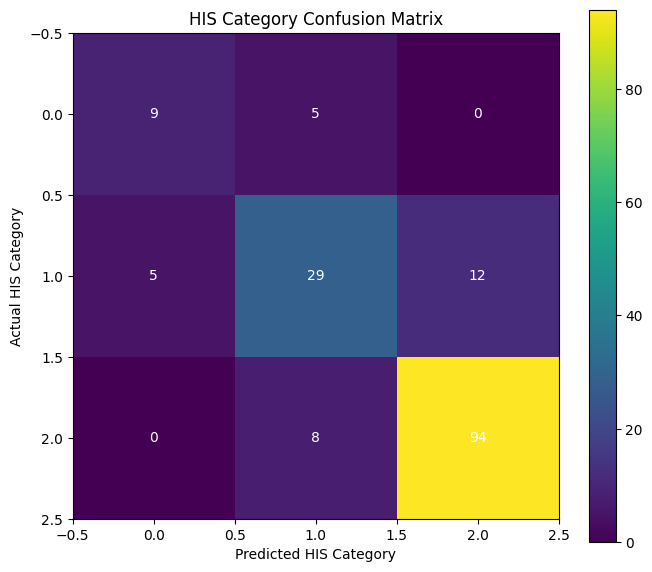

[[ 9  5  0]
 [ 5 29 12]
 [ 0  8 94]]


In [ ]:
from sklearn.metrics import confusion_matrix
import matplotlib.pyplot as plt

# Predict using your trained model
y_pred = xgb_model.predict(X_test)

# Create confusion matrix
cm = confusion_matrix(
    y_test,
    y_pred
)

# Plot confusion matrix
plt.figure(figsize=(7,6))

plt.imshow(cm)

plt.colorbar()

# Axis labels
plt.xlabel("Predicted HIS Category")
plt.ylabel("Actual HIS Category")

# Title
plt.title("HIS Category Confusion Matrix")

# Show values inside matrix
for i in range(len(cm)):
    for j in range(len(cm)):
        plt.text(
            j,
            i,
            cm[i, j],
            ha='center',
            va='center',
            color='white'
        )

plt.tight_layout()

plt.show()

# Print matrix
print(cm)

In [ ]:
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, classification_report
from xgboost import XGBClassifier

# Train Model
xgb_model.fit(X_train, y_train)

# Predict
y_pred = xgb_model.predict(X_test)

# Accuracy
accuracy = accuracy_score(y_test, y_pred)

print("Accuracy:", round(accuracy * 100, 2), "%")

# Classification Report
print("\nClassification Report:")
print(classification_report(y_test, y_pred))

Accuracy: 81.48 %

Classification Report:
              precision    recall  f1-score   support

           0       0.64      0.64      0.64        14
           1       0.69      0.63      0.66        46
           2       0.89      0.92      0.90       102

    accuracy                           0.81       162
   macro avg       0.74      0.73      0.74       162
weighted avg       0.81      0.81      0.81       162



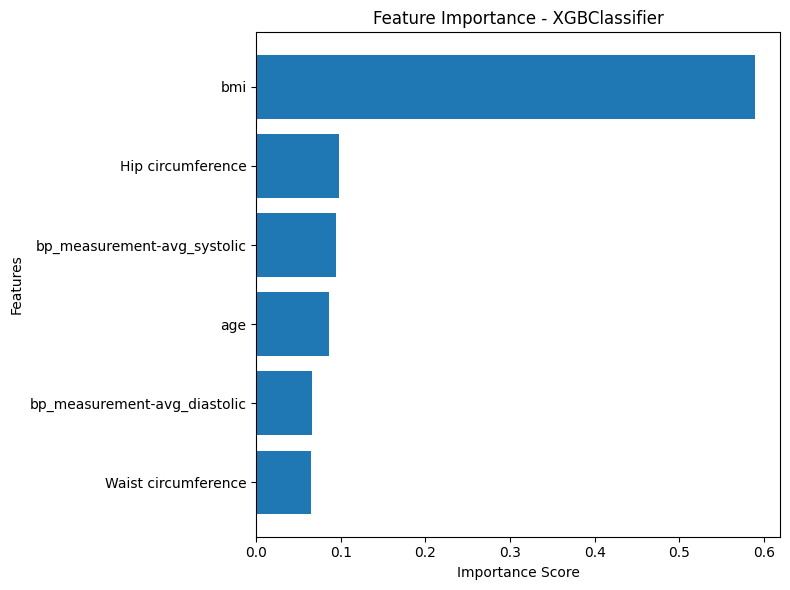

                        Feature  Importance
0                           bmi    0.589690
1             Hip circumference    0.098366
4   bp_measurement-avg_systolic    0.094412
2                           age    0.086379
5  bp_measurement-avg_diastolic    0.066200
3           Waist circumference    0.064953


In [ ]:
import pandas as pd
import matplotlib.pyplot as plt

fi = pd.DataFrame({
    'Feature': X_train.columns,
    'Importance': xgb_model.feature_importances_
})

fi = fi.sort_values(by='Importance', ascending=True)

plt.figure(figsize=(8,6))
plt.barh(fi['Feature'], fi['Importance'])
plt.xlabel('Importance Score')
plt.ylabel('Features')
plt.title('Feature Importance - XGBClassifier')
plt.tight_layout()
plt.show()

print(fi.sort_values(by='Importance', ascending=False))

In [ ]:
from sklearn.model_selection import GridSearchCV

param_grid = {
    'max_depth': [3, 5, 7, 9],
    'n_estimators': [50, 100, 200, 500],
    'learning_rate': [0.001, 0.01, 0.05, 0.1, 0.2]
}

grid = GridSearchCV(
    XGBOrdinal(),
    param_grid,
    cv=5,
    scoring='accuracy',
    n_jobs=-1,
    error_score='raise'
)

grid.fit(X_train, y_train)

print("Best Parameters:", grid.best_params_)
print("Best CV Accuracy:", grid.best_score_)

Best Parameters: {'learning_rate': 0.01, 'max_depth': 3, 'n_estimators': 200}
Best CV Accuracy: 0.8320000000000001


In [ ]:
import pandas as pd
print(pd.Series(y_train).value_counts().nunique() == 1)


False


In [ ]:
model = XGBOrdinal(
    random_state=42,
    max_depth=3,
    n_estimators=200,
    learning_rate=0.1
)
model.fit(X_train, y_train)

XGBOrdinal(base_score=None, booster=None, callbacks=None,
           colsample_bylevel=None, colsample_bynode=None, colsample_bytree=None,
           device=None, early_stopping_rounds=None, enable_categorical=False,
           eval_metric=None, feature_types=None, feature_weights=None,
           gamma=None, grow_policy=None, importance_type=None,
           interaction_constraints=None, learning_rate=0.1, max_bin=None,
           max_cat_threshold=None, max_cat_to_onehot=None, max_delta_step=None,
           max_depth=3, max_leaves=None, min_child_weight=None, missing=nan,
           monotone_constraints=None, multi_strategy=None, n_estimators=200,
           n_jobs=None, num_parallel_tree=None, ...)

In [ ]:
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report
import pandas as pd

# Convert labels if needed
risk_mapping = {
    'Low': 0,
    'Intermediate': 1,
    'High': 2
}

if y_test.dtype == 'object':
    y_test = y_test.map(risk_mapping)

# Remove NaN from y_test
mask = ~pd.isna(y_test)

y_test_clean = y_test[mask]
y_pred_clean = pd.Series(y_pred).iloc[mask.values]

print("Accuracy:", accuracy_score(y_test_clean, y_pred_clean))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test_clean, y_pred_clean))

print("\nClassification Report:")
print(classification_report(
    y_test_clean,
    y_pred_clean,
    target_names=['Low', 'Intermediate', 'High']
))

Accuracy: 0.8148148148148148

Confusion Matrix:
[[ 9  5  0]
 [ 5 29 12]
 [ 0  8 94]]

Classification Report:
              precision    recall  f1-score   support

         Low       0.64      0.64      0.64        14
Intermediate       0.69      0.63      0.66        46
        High       0.89      0.92      0.90       102

    accuracy                           0.81       162
   macro avg       0.74      0.73      0.74       162
weighted avg       0.81      0.81      0.81       162



In [ ]:
from sklearn.model_selection import cross_val_score

scores = cross_val_score(
    model,
    X_selected,
    y,
    cv=5,
    scoring='accuracy'
)

print(scores)
print(scores.mean())

[0.77777778 0.62037037 0.73831776 0.70093458 0.78504673]
0.7244894427137418


In [ ]:
y_pred = model.predict(X_test)
print(y_pred[:10])

[2 2 0 2 2 2 0 2 2 1]


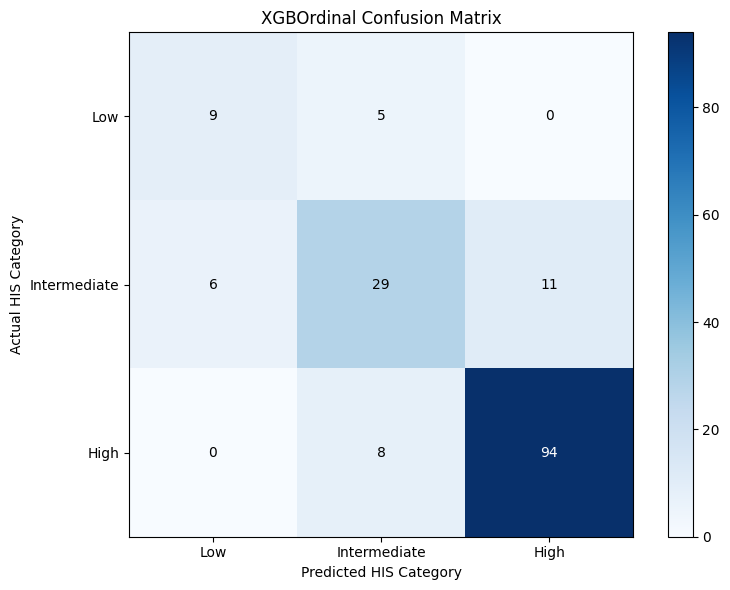


Confusion Matrix:
[[ 9  5  0]
 [ 6 29 11]
 [ 0  8 94]]


In [ ]:
from sklearn.metrics import confusion_matrix
import matplotlib.pyplot as plt
import numpy as np

# Prediction
y_pred = model.predict(X_test)

# Confusion Matrix
cm = confusion_matrix(y_test, y_pred)

labels = ['Low', 'Intermediate', 'High']

plt.figure(figsize=(8,6))
plt.imshow(cm, cmap='Blues')
plt.colorbar()

plt.xticks(np.arange(len(labels)), labels)
plt.yticks(np.arange(len(labels)), labels)

plt.xlabel("Predicted HIS Category")
plt.ylabel("Actual HIS Category")
plt.title("XGBOrdinal Confusion Matrix")

for i in range(cm.shape[0]):
    for j in range(cm.shape[1]):
        plt.text(
            j, i, cm[i, j],
            ha='center',
            va='center',
            color='white' if cm[i, j] > cm.max()/2 else 'black'
        )

plt.tight_layout()
plt.show()

print("\nConfusion Matrix:")
print(cm)

In [ ]:
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score
from xgboost import XGBClassifier
import pandas as pd

risk_mapping = {
    'Low': 0,
    'Intermediate': 1,
    'High': 2
}

df['HIS_Category_Encoded'] = df['HIS Category'].map(risk_mapping)

X_final = df[[
    'bmi',
    'Hip circumference',
    'bp_measurement-avg_systolic',
    'age',
    'Waist circumference',
    'bp_measurement-avg_diastolic',
]]

y = df['HIS_Category_Encoded']

# Handle missing values
X_final = X_final.fillna(0)

# Convert categorical columns if any
for col in X_final.columns:
    if X_final[col].dtype == 'object':
        X_final[col] = X_final[col].astype('category').cat.codes


model.fit(X_train, y_train)

# Predict
y_pred = model.predict(X_test)

# Accuracy
accuracy = accuracy_score(y_test, y_pred)
print("Accuracy:", accuracy)

# New sample prediction
new_data = pd.DataFrame({
    'bmi': [32],
    'Hip circumference': [110],
    'bp_measurement-avg_systolic': [130],
    'age': [52],
    'Waist circumference': [108],
    'bp_measurement-avg_diastolic': [128],
})

new_data = new_data[X_train.columns]
prediction = model.predict(new_data)

risk_labels = {
    0: 'Low',
    1: 'Intermediate',
    2: 'High'
}

print("Predicted HIS Category:", risk_labels[int(prediction[0])])

Accuracy: 0.8148148148148148
Predicted HIS Category: High


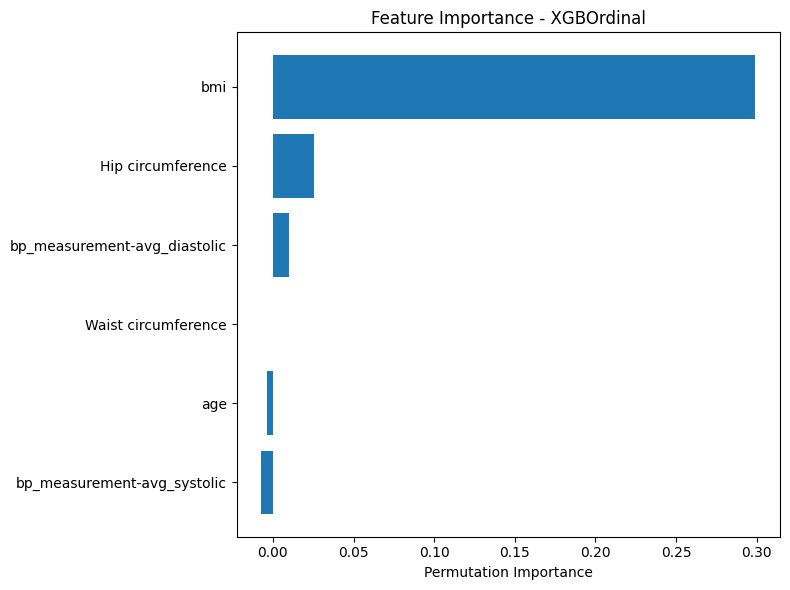

                        Feature    Importance
0                           bmi  2.990741e-01
1             Hip circumference  2.561728e-02
5  bp_measurement-avg_diastolic  9.876543e-03
3           Waist circumference -3.885781e-17
2                           age -3.703704e-03
4   bp_measurement-avg_systolic -7.098765e-03


In [ ]:
from sklearn.inspection import permutation_importance
import pandas as pd
import matplotlib.pyplot as plt

result = permutation_importance(
    model,
    X_test,
    y_test,
    n_repeats=20,
    random_state=42,
    scoring='accuracy'
)

# DataFrame
fi = pd.DataFrame({
    'Feature': X_test.columns,
    'Importance': result.importances_mean
})

fi = fi.sort_values('Importance', ascending=True)

# Plot
plt.figure(figsize=(8,6))
plt.barh(fi['Feature'], fi['Importance'])
plt.xlabel("Permutation Importance")
plt.title("Feature Importance - XGBOrdinal")
plt.tight_layout()
plt.show()

# Top Features
print(fi.sort_values('Importance', ascending=False))